# Task 4: Trend Prediction Analysis (Netflix Dataset)

**Goal:** analyze how Netflix's content has grown over time and forecast future content additions.

**Workflow**
1. Prepare release-year data
2. Analyze yearly content trends
3. Build forecasting models
4. Visualize future predictions
5. Interpret results

**Input:** `netflix_cleaned.csv` from Task 1.

## Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")   # statsmodels prints convergence notes for small series

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a3a29c"
TYPE_COLORS = {"Movie": BLUE, "TV Show": ORANGE}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "figure.dpi": 110,
})

df = pd.read_csv("netflix_cleaned.csv", parse_dates=["date_added"])
print("Titles:", len(df))
print("Added between", df["date_added"].min().date(), "and", df["date_added"].max().date())

Titles: 8786
Added between 2008-01-01 and 2021-09-25


## Step 1: Prepare release-year data

There are two time columns, and they answer different questions:
- `release_year`: when a title was made. Shows trends in **what content exists** on Netflix by era.
- `date_added`: when Netflix added it. Shows **how fast the catalog grows**, which is what a content team would want forecast.

Both are prepared here.

In [2]:
release = pd.crosstab(df["release_year"], df["type"])
release["Total"] = release.sum(axis=1)
release["TV share %"] = (release["TV Show"] / release["Total"] * 100).round(1)
release.loc[2010:]

type,Movie,TV Show,Total,TV share %
release_year,,,,
2010,153,39,192,20.3
2011,145,40,185,21.6
2012,173,63,236,26.7
2013,225,61,286,21.3
2014,263,88,351,25.1
2015,396,159,555,28.6
2016,658,243,901,27.0
2017,765,265,1030,25.7
2018,766,378,1144,33.0


**A data trap in recent release years.** The dataset ends in September 2021, and many titles reach Netflix years after release (Task 2 found a median of 2 years for movies). So titles released in 2019 to 2021 are **undercounted**: many of them had not been added yet when the data was collected. The next cell measures how big this effect is.

In [3]:
# For release years 2012 to 2016 (old enough to be fully observed), how long until titles were added?
mature = df[df["release_year"].between(2012, 2016)]
lag_share = pd.Series({
    f"within {k} year{'s' if k != 1 else ''}": (mature["years_to_netflix"] <= k).mean() * 100
    for k in [0, 1, 2, 3, 5]
}).round(1)
lag_share.to_frame("% of titles added")

,% of titles added
within 0 years,11.4
within 1 year,30.2
within 2 years,43.0
within 3 years,56.9
within 5 years,81.2


Only a minority of titles are added in their release year, and a large share arrive more than two years later. A drop in release-year counts after 2018 therefore **does not** mean less content is being made. For forecasting catalog growth, `date_added` is the reliable series.

In [4]:
# Monthly additions: the series used for forecasting
monthly = df.set_index("date_added").resample("MS").size().rename("titles_added")
monthly_type = df.groupby([pd.Grouper(key="date_added", freq="MS"), "type"]).size().unstack(fill_value=0)

# September 2021 only covers 25 days, so it is excluded as a partial month.
# Before 2016 additions were tiny and irregular (Netflix's catalog build-up began in 2016).
START, END = "2016-01", "2021-08"
y = monthly[START:END].astype(float)
y_type = monthly_type[START:END].astype(float)
print(f"Modeling series: {y.index.min():%b %Y} to {y.index.max():%b %Y}, {len(y)} months")
y.tail()

Modeling series: Jan 2016 to Aug 2021, 68 months


date_added
2021-04-01    188.0
2021-05-01    132.0
2021-06-01    207.0
2021-07-01    257.0
2021-08-01    178.0
Freq: MS, Name: titles_added, dtype: float64

## Step 2: Analyze yearly content trends

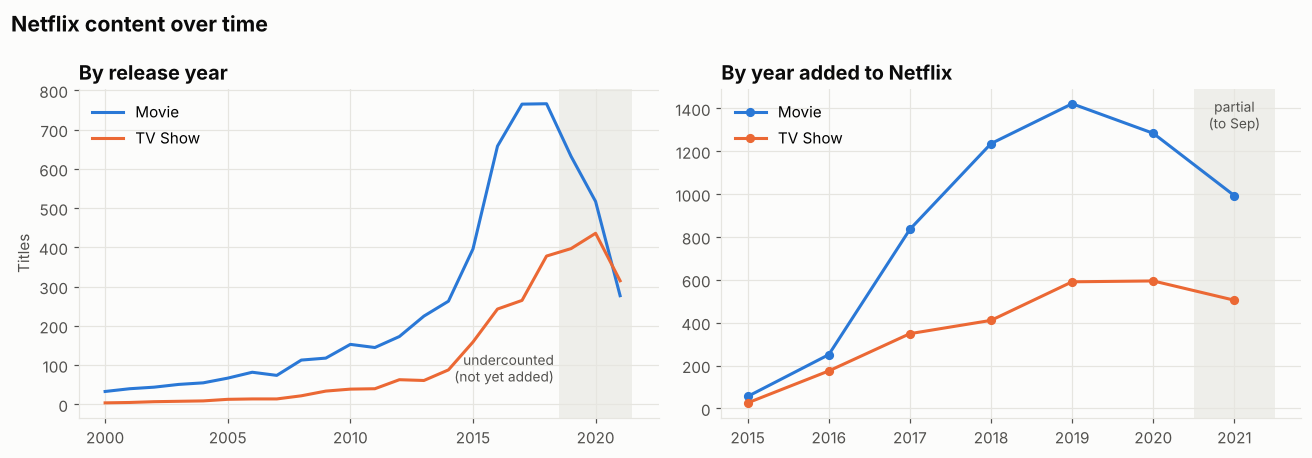

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

r = release.loc[2000:2021]
for t in ["Movie", "TV Show"]:
    axes[0].plot(r.index, r[t], color=TYPE_COLORS[t], lw=2, label=t)
axes[0].axvspan(2018.5, 2021.5, color=GRID, alpha=0.6, lw=0)
axes[0].text(2018.3, 50, "undercounted\n(not yet added)", ha="right", va="bottom", fontsize=9, color=MUTED)
axes[0].set_title("By release year", loc="left")
axes[0].set_ylabel("Titles"); axes[0].legend(frameon=False, loc="upper left")

added_year = pd.crosstab(df["date_added"].dt.year, df["type"]).loc[2015:]
for t in ["Movie", "TV Show"]:
    axes[1].plot(added_year.index, added_year[t], color=TYPE_COLORS[t], lw=2, marker="o", ms=5, label=t)
axes[1].axvspan(2020.5, 2021.5, color=GRID, alpha=0.6, lw=0)
axes[1].text(2021, axes[1].get_ylim()[1] * 0.97, "partial\n(to Sep)", ha="center", va="top", fontsize=9, color=MUTED)
axes[1].set_title("By year added to Netflix", loc="left")
axes[1].legend(frameon=False, loc="upper left")

fig.suptitle("Netflix content over time", x=0.01, ha="left", fontweight="bold", fontsize=14, color=INK)
fig.tight_layout()
fig.savefig("01_yearly_trends.png", bbox_inches="tight", dpi=150)
plt.show()

In [6]:
# Year-over-year growth in additions (full years only)
yearly = df[df["date_added"].dt.year.between(2015, 2020)].groupby(df["date_added"].dt.year).size()
growth = pd.DataFrame({"titles_added": yearly, "YoY growth %": (yearly.pct_change() * 100).round(1)})
growth

,titles_added,YoY growth %
date_added,,
2015,82,NaN
2016,426,419.5
2017,1185,178.2
2018,1647,39.0
2019,2013,22.2
2020,1879,-6.7


In [7]:
# Compare Jan to Aug across years, so 2021 can be compared fairly with earlier years
jan_aug = df[df["date_added"].dt.month <= 8].groupby(df["date_added"].dt.year).size().loc[2017:2021]
pd.DataFrame({"Jan to Aug additions": jan_aug, "change vs prior year %": (jan_aug.pct_change() * 100).round(1)})

,Jan to Aug additions,change vs prior year %
date_added,,
2017,743,NaN
2018,994,33.8
2019,1228,23.5
2020,1221,-0.6
2021,1315,7.7


**Trend observations**
- Additions grew explosively from 2015 to 2017 (several hundred percent per year), then growth slowed each year and **peaked in 2019** at about 2,000 titles.
- 2020 was about 7% lower than 2019 (the first decline, in the year COVID-19 disrupted production). Comparing January to August only, which is a fair comparison with partial 2021, 2021 was about 8% above 2020 and back near the 2019 level.
- So the catalog has moved from rapid expansion to a **plateau of roughly 150 to 170 titles a month**, about 2,000 a year.
- By release year, counts peak around 2018 and TV's share appears to jump to about 50%. Both are mostly data artifacts: recent titles have not all been added yet, and movies reach Netflix later than TV shows, so recent movies are undercounted most.

## Step 3: Build forecasting models

**Candidates**

| Model | Idea |
|---|---|
| Seasonal naive | Next month = same month last year |
| 12-month average | Next month = average of the last 12 months |
| Linear trend | Straight line through the whole history |
| Holt-Winters | Exponential smoothing with damped trend and monthly seasonality |
| Damped trend (ETS) | Exponential smoothing with a trend that flattens out, no seasonality |
| ARIMA(1,1,1) | Classic statistical time series model |

**Evaluation: rolling-origin backtest.** With only 68 months of data, a single train/test split is unreliable. Instead, each model is trained on data up to a cutoff, asked to forecast the next 6 months, and scored against what actually happened. This is repeated at 4 cutoffs, moving forward 6 months each time. Metrics:
- **MAE**: average error in titles per month
- **MAPE**: average error as a percentage

In [8]:
def fc_seasonal_naive(train, h):
    return np.resize(train[-12:].values, h)

def fc_mean12(train, h):
    return np.repeat(train[-12:].mean(), h)

def fc_linear(train, h):
    t = np.arange(len(train)).reshape(-1, 1)
    model = LinearRegression().fit(t, train.values)
    return model.predict(np.arange(len(train), len(train) + h).reshape(-1, 1))

def fc_holt_winters(train, h):
    model = ExponentialSmoothing(train, trend="add", damped_trend=True,
                                 seasonal="add", seasonal_periods=12).fit()
    return model.forecast(h).values

def fc_damped_ets(train, h):
    model = ETSModel(train, error="add", trend="add", damped_trend=True).fit(disp=False)
    return model.forecast(h).values

def fc_arima(train, h):
    return ARIMA(train, order=(1, 1, 1)).fit().forecast(h).values

MODELS = {
    "Seasonal naive": fc_seasonal_naive,
    "12-month average": fc_mean12,
    "Linear trend": fc_linear,
    "Holt-Winters": fc_holt_winters,
    "Damped trend (ETS)": fc_damped_ets,
    "ARIMA(1,1,1)": fc_arima,
}

In [9]:
H = 6
cutoffs = [len(y) - H * k for k in [4, 3, 2, 1]]   # 4 folds, each forecasting 6 months

rows = []
for name, fc in MODELS.items():
    for c in cutoffs:
        train, test = y.iloc[:c], y.iloc[c:c + H]
        pred = fc(train, H)
        rows.append({
            "model": name,
            "fold": f"{test.index[0]:%b %Y} to {test.index[-1]:%b %Y}",
            "MAE": np.mean(np.abs(pred - test.values)),
            "MAPE": np.mean(np.abs(pred - test.values) / test.values) * 100,
        })

bt = pd.DataFrame(rows)
scores = bt.groupby("model")[["MAE", "MAPE"]].mean().sort_values("MAE").round(1)
scores

,MAE,MAPE
model,,
12-month average,35.0,21.1
Seasonal naive,36.6,21.2
"ARIMA(1,1,1)",37.0,20.7
Damped trend (ETS),38.0,24.9
Holt-Winters,43.0,27.4
Linear trend,49.0,34.4


In [10]:
# Error per fold, to check that the ranking is consistent and not driven by one period
bt.pivot(index="model", columns="fold", values="MAE").loc[scores.index].round(0)

fold,Mar 2020 to Aug 2020,Mar 2021 to Aug 2021,Sep 2019 to Feb 2020,Sep 2020 to Feb 2021
model,,,,
12-month average,22.0,48.0,53.0,18.0
Seasonal naive,15.0,45.0,37.0,49.0
"ARIMA(1,1,1)",18.0,51.0,57.0,22.0
Damped trend (ETS),38.0,41.0,47.0,25.0
Holt-Winters,40.0,53.0,41.0,38.0
Linear trend,59.0,41.0,41.0,55.0


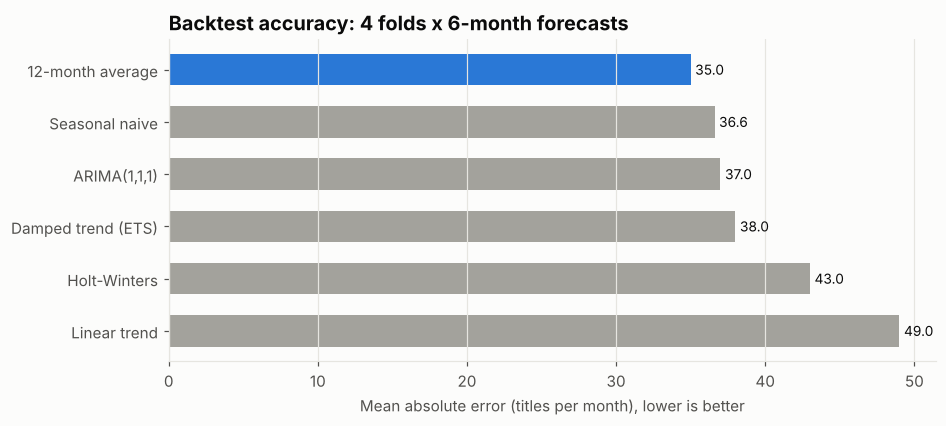

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = scores.index[::-1]
colors = [BLUE if m == "12-month average" else GRAY for m in order]
bars = ax.barh(order, scores.loc[order, "MAE"], color=colors, height=0.6)
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9, color=INK)
ax.set_xlabel("Mean absolute error (titles per month), lower is better")
ax.set_title("Backtest accuracy: 4 folds x 6-month forecasts", loc="left")
ax.grid(axis="y", visible=False)
fig.savefig("02_model_comparison.png", bbox_inches="tight", dpi=150)
plt.show()

**Reading the backtest**
- **The simple 12-month average is the most accurate model** (about 35 titles per month off, around 21%). Seasonal naive and ARIMA are close behind.
- **Linear trend is the worst on average.** A straight line through 2016 to 2021 is dominated by the 2016 to 2018 boom, so it keeps predicting growth that stopped. This is the main lesson of the task: extrapolating early growth overestimates future additions.
- **Holt-Winters (trend plus seasonality) is second worst.** With only about 5 years of data, the fitted seasonal pattern is mostly noise.
- **Errors vary a lot between folds** (from under 20 to over 50 titles per month for the same model), and the top models trade places from fold to fold. The differences between the top four are small compared with that variation, so the takeaway is "simple level-based models beat trend extrapolation", not that one model is clearly best.

**Model chosen: 12-month average**, the best performer and the easiest to explain. A model that cannot beat a simple average is not worth its extra complexity. Because it does not produce prediction intervals on its own, the 80% interval is built from its **actual backtest errors**. The damped trend ETS model is shown alongside as a second opinion.

## Step 4: Visualize future predictions

In [12]:
H_FUTURE = 16   # Sep 2021 to Dec 2022
future_idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(), periods=H_FUTURE, freq="MS")

# Point forecast: average of the last 12 months
point = y[-12:].mean()

# 80% interval from the model's own backtest errors (actual minus forecast, all folds)
errors = []
for c in cutoffs:
    train, test = y.iloc[:c], y.iloc[c:c + H]
    errors.extend(test.values - fc_mean12(train, H))
errors = np.array(errors)
lo_err, hi_err = np.percentile(errors, [10, 90])

fcst = pd.DataFrame({
    "forecast": point,
    "low (80%)": max(point + lo_err, 0),
    "high (80%)": point + hi_err,
}, index=future_idx).round(0)

# Second opinion: damped trend ETS
ets = ETSModel(y, error="add", trend="add", damped_trend=True).fit(disp=False)
fcst["ETS forecast"] = ets.forecast(H_FUTURE).values.round(0)

print(f"Backtest errors used for the interval: {len(errors)}")
print(f"Point forecast: {point:.0f} titles/month, 80% interval {fcst['low (80%)'].iloc[0]:.0f} to {fcst['high (80%)'].iloc[0]:.0f}")
fcst.head(6)

Backtest errors used for the interval: 24
Point forecast: 164 titles/month, 80% interval 125 to 222


,forecast,low (80%),high (80%),ETS forecast
2021-09-01,164.0,125.0,222.0,177.0
2021-10-01,164.0,125.0,222.0,177.0
2021-11-01,164.0,125.0,222.0,178.0
2021-12-01,164.0,125.0,222.0,178.0
2022-01-01,164.0,125.0,222.0,179.0
2022-02-01,164.0,125.0,222.0,179.0


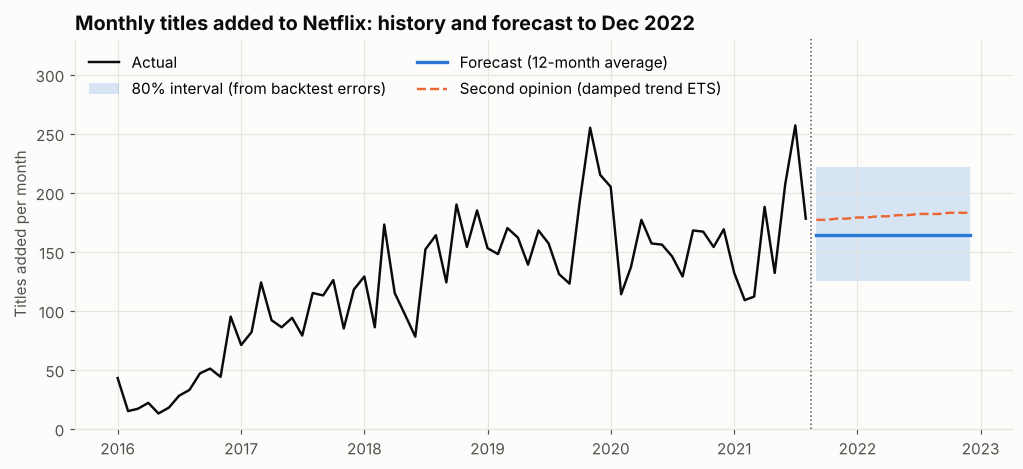

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(y.index, y.values, color=INK, lw=1.6, label="Actual")
ax.fill_between(fcst.index, fcst["low (80%)"], fcst["high (80%)"], color=BLUE, alpha=0.18, lw=0,
                label="80% interval (from backtest errors)")
ax.plot(fcst.index, fcst["forecast"], color=BLUE, lw=2.2, label="Forecast (12-month average)")
ax.plot(fcst.index, fcst["ETS forecast"], color=ORANGE, lw=1.6, ls="--", label="Second opinion (damped trend ETS)")
ax.axvline(fcst.index[0] - pd.Timedelta(days=15), color=MUTED, lw=1, ls=":")
ax.set_title("Monthly titles added to Netflix: history and forecast to Dec 2022", loc="left")
ax.set_ylabel("Titles added per month")
ax.legend(frameon=False, loc="upper left", ncol=2)
ax.set_ylim(0, 330)
fig.savefig("03_forecast.png", bbox_inches="tight", dpi=150)
plt.show()

In [14]:
# Yearly view: full-year 2021 estimate (actual Jan to Aug + forecast Sep to Dec) and 2022
actual_by_year = y.groupby(y.index.year).sum()
f_by_year = fcst.groupby(fcst.index.year)[["forecast", "ETS forecast"]].sum()

# Yearly interval: monthly errors partly cancel out over a year, so scale the spread by sqrt(12)
# (assumes months are independent, which is an approximation)
year_spread = 1.2816 * errors.std() * np.sqrt(12)

summary = pd.DataFrame({
    "actual": [actual_by_year[2019], actual_by_year[2020], actual_by_year[2021], 0],
    "forecast": [0, 0, f_by_year.loc[2021, "forecast"], f_by_year.loc[2022, "forecast"]],
}, index=[2019, 2020, 2021, 2022])
summary["total (estimate)"] = summary["actual"] + summary["forecast"]
summary["ETS total"] = summary["actual"] + [0, 0, f_by_year.loc[2021, "ETS forecast"], f_by_year.loc[2022, "ETS forecast"]]
summary = summary.astype(int)
summary["80% range"] = ""
summary.loc[2022, "80% range"] = (f"{summary.loc[2022, 'total (estimate)'] - year_spread:,.0f} to "
                                  f"{summary.loc[2022, 'total (estimate)'] + year_spread:,.0f}")
summary

,actual,forecast,total (estimate),ETS total,80% range
2019,2013,0,2013,2013,
2020,1879,0,1879,1879,
2021,1315,656,1971,2025,
2022,0,1968,1968,2175,"1,774 to 2,162"


In [15]:
# Same method applied to Movies and TV Shows separately
by_type = pd.DataFrame({
    "2020 actual": y_type.loc["2020"].sum().astype(int),
    "monthly avg, last 12 months": y_type[-12:].mean().round(0),
})
by_type["2022 forecast"] = (by_type["monthly avg, last 12 months"] * 12).astype(int)
by_type["2022 share %"] = (by_type["2022 forecast"] / by_type["2022 forecast"].sum() * 100).round(1)
by_type

,2020 actual,"monthly avg, last 12 months",2022 forecast,2022 share %
type,,,,
Movie,1284,109.0,1308,66.5
TV Show,595,55.0,660,33.5


In [16]:
# How the TV share of additions has moved, with the 2022 forecast share
tv_share = (y_type["TV Show"].groupby(y_type.index.year).sum() / y.groupby(y.index.year).sum() * 100).round(1)
tv_share.index = tv_share.index.astype(str)
tv_share.loc["2022 (forecast)"] = by_type.loc["TV Show", "2022 share %"]
tv_share.to_frame("TV share of additions %")

,TV share of additions %
date_added,
2016,41.1
2017,29.5
2018,25.0
2019,29.4
2020,31.7
2021,33.5
2022 (forecast),33.5


## Step 5: Interpret results

**Findings**
1. **Growth has plateaued.** After explosive growth from 2015 to 2017 and a peak in 2019, Netflix has been adding a fairly stable number of titles: about 2,000 a year, or 150 to 170 a month. 2020 dipped about 7%, and 2021 recovered to around the 2019 level.
2. **The forecast is flat, not rising.** The selected model forecasts about 164 titles a month, roughly 1,970 titles in 2022. The ETS second opinion picks up the strong mid-2021 months and is somewhat higher (about 2,175). Both say the same thing: a stable level, not a return to rapid growth.
3. **Simple models won.** In backtesting, a 12-month average was the most accurate model. Trend extrapolation was the worst, because it projects the early boom forward. The top models were close, and their ranking changed from fold to fold.
4. **Uncertainty is wide.** The 80% interval for a single month spans roughly 125 to 222 titles. Individual months swing a lot (for example, July 2021 had 257 additions), driven by licensing deals and release slates that this data does not capture.
5. **Mix is shifting toward TV.** TV's share of additions fell to about 25% in 2018 as movie additions boomed, then rose steadily to about 34% in 2021. The last 12 months put TV at about a third of 2022 additions, so the shift holds but is not projected to accelerate.
6. **Release-year counts are misleading for recent years.** Only about 43% of titles reach Netflix within 2 years of release, so titles from 2019 to 2021 look like they are declining only because many had not been added yet.

**Limitations**
- Only about 5.5 years of monthly data, and the series contains a regime change (boom, then plateau). Any forecast beyond a year or so is low-confidence.
- The data shows titles **added**, not titles **removed**, so this forecasts inflow, not total catalog size.
- External factors (licensing budgets, production delays such as COVID-19 in 2020, competition from new streaming services) drive additions but are not in the data.

**Possible improvements**
- Add external variables such as content spending or subscriber numbers.
- Re-run the forecast as new months of data arrive, and compare forecasts with actuals.